In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [3]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Download the dataset
housing = fetch_california_housing(as_frame=True)

# Convert dataset into DataFrame
df = housing.frame

# Display first 5 rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.to_csv('California_Housing.csv', index=False)

In [5]:
from google.colab import files

files.download('California_Housing.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files

uploaded = files.upload()

Saving California_Housing.csv to California_Housing (1).csv


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('California_Housing.csv')

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [9]:
df.shape

(20640, 9)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [11]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [12]:
df.isnull().sum()


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [13]:
df.duplicated().sum()

np.int64(0)

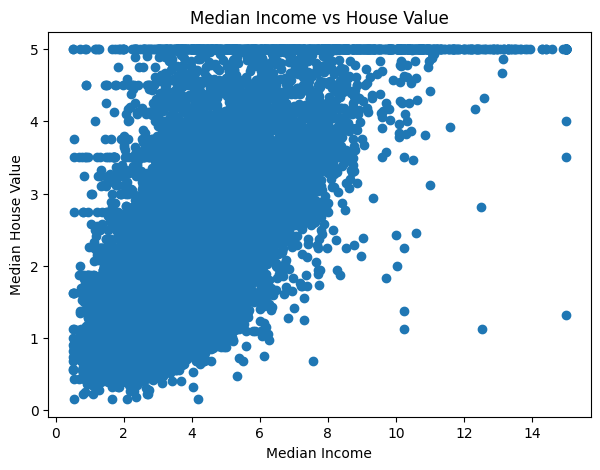

In [14]:
plt.figure(figsize=(7,5))

plt.scatter(df['MedInc'], df['MedHouseVal'])

plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.title('Median Income vs House Value')

plt.show()

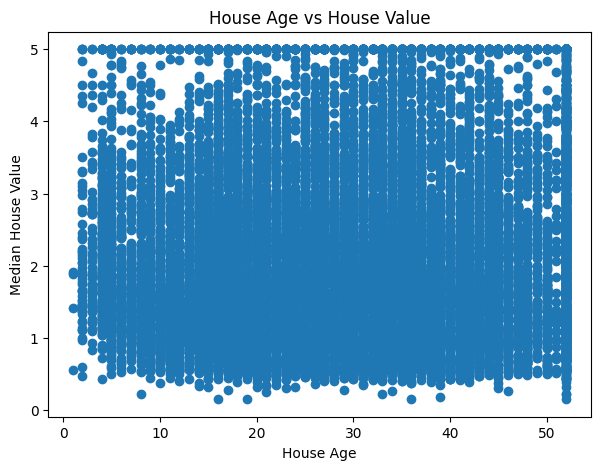

In [15]:
plt.figure(figsize=(7,5))

plt.scatter(df['HouseAge'], df['MedHouseVal'])

plt.xlabel('House Age')
plt.ylabel('Median House Value')
plt.title('House Age vs House Value')

plt.show()

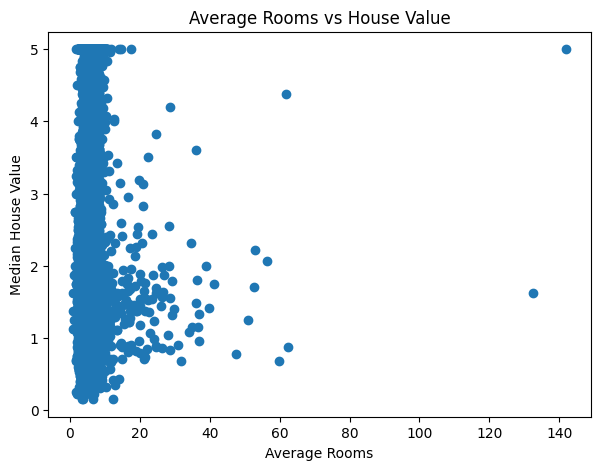

In [16]:
plt.figure(figsize=(7,5))

plt.scatter(df['AveRooms'], df['MedHouseVal'])

plt.xlabel('Average Rooms')
plt.ylabel('Median House Value')
plt.title('Average Rooms vs House Value')

plt.show()

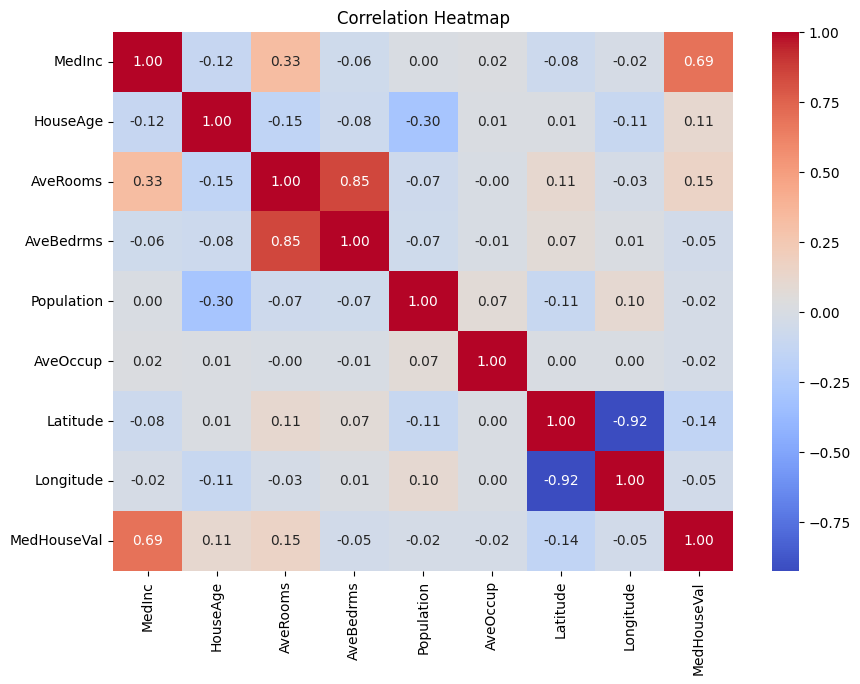

In [17]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [18]:
sample = df[['MedInc', 'HouseAge', 'MedHouseVal']].head(5)

sample

,MedInc,HouseAge,MedHouseVal
0,8.3252,41.0,4.526
1,8.3014,21.0,3.585
2,7.2574,52.0,3.521
3,5.6431,52.0,3.413
4,3.8462,52.0,3.422


In [19]:
X = np.column_stack((
    np.ones(len(sample)),
    sample['MedInc'],
    sample['HouseAge']
))

y = sample['MedHouseVal'].values

print("Design Matrix X:")
print(X)

print("\nTarget Vector Y:")
print(y)

Design Matrix X:
[[ 1.      8.3252 41.    ]
 [ 1.      8.3014 21.    ]
 [ 1.      7.2574 52.    ]
 [ 1.      5.6431 52.    ]
 [ 1.      3.8462 52.    ]]

Target Vector Y:
[4.526 3.585 3.521 3.413 3.422]


In [20]:
XT = X.T

XTX = XT @ X

print("X Transpose X:")
print(XTX)

X Transpose X:
[[5.00000000e+00 3.33733000e+01 2.18000000e+02]
 [3.33733000e+01 2.37529884e+02 1.38649100e+03]
 [2.18000000e+02 1.38649100e+03 1.02340000e+04]]


In [21]:
XTY = XT @ y

print("X Transpose Y:")
print(XTY)

X Transpose Y:
[ 18.467     125.4152763 799.363    ]


In [22]:
B = np.linalg.solve(XTX, XTY)

print("Regression Coefficients:")
print(B)

print("b0 =", B[0])
print("b1 =", B[1])
print("b2 =", B[2])

Regression Coefficients:
[1.95717671 0.19330102 0.01022947]
b0 = 1.9571767091699699
b1 = 0.19330101517517945
b2 = 0.010229466442221698


In [23]:
predicted = X @ B

residual = y - predicted

print("Actual Values:", y)

print("Predicted Values:", predicted)

print("Residuals:", residual)

Actual Values: [4.526 3.585 3.521 3.413 3.422]
Predicted Values: [3.98585444 3.77666455 3.89197175 3.57992592 3.23258333]
Residuals: [ 0.54014556 -0.19166455 -0.37097175 -0.16692592  0.18941667]


In [24]:
X = df.drop('MedHouseVal', axis=1)

y = df['MedHouseVal']

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (16512, 8)
Testing Data: (4128, 8)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (16512, 8)
Testing Data: (4128, 8)


In [28]:
correlations = df.corr()['MedHouseVal'].drop('MedHouseVal')

print(correlations.sort_values(ascending=False))

MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64


In [29]:
best_feature = correlations.abs().idxmax()

print("Selected Feature:", best_feature)

X_single_train = X_train[[best_feature]]

X_single_test = X_test[[best_feature]]

single_model = LinearRegression()

single_model.fit(X_single_train, y_train)

single_pred = single_model.predict(X_single_test)

print("Intercept:", single_model.intercept_)

print("Coefficient:", single_model.coef_)

Selected Feature: MedInc
Intercept: 0.4445972916907879
Coefficient: [0.41933849]


In [30]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [31]:
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

Intercept: -37.02327770606406
      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708


In [32]:

y_pred = model.predict(X_test)

In [33]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


In [34]:
single_r2 = r2_score(y_test, single_pred)

multiple_r2 = r2_score(y_test, y_pred)

print("Single Feature R2:", single_r2)

print("Multiple Feature R2:", multiple_r2)

Single Feature R2: 0.45885918903846656
Multiple Feature R2: 0.5757877060324511


In [35]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

n = len(y_test)

p = X_test.shape[1]

adjusted_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

print("Adjusted R2:", adjusted_r2)

MAE: 0.5332001304956551
MSE: 0.555891598695244
RMSE: 0.7455813830127761
R2 Score: 0.5757877060324511
Adjusted R2: 0.5749637928613561


In [36]:
results = pd.DataFrame({
    'Metric': ['R2 Score'],
    'Single Linear Regression': [single_r2],
    'Multiple Linear Regression': [multiple_r2]
})

results

,Metric,Single Linear Regression,Multiple Linear Regression
0,R2 Score,0.458859,0.575788


In [37]:
residuals = y_test - y_pred

print(residuals.head())

20046   -0.242123
3024    -1.306017
15663    2.290351
20484   -0.652926
9814     0.175343
Name: MedHouseVal, dtype: float64


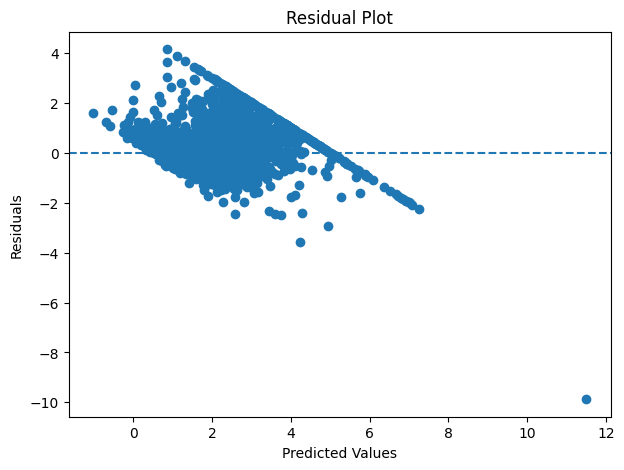

In [38]:
plt.figure(figsize=(7,5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Values')

plt.ylabel('Residuals')

plt.title('Residual Plot')

plt.show()

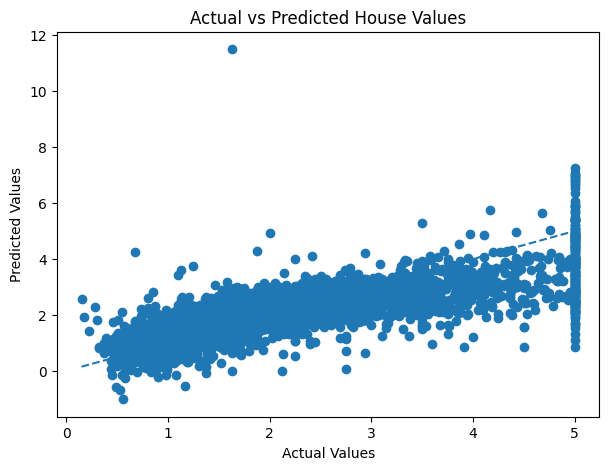

In [39]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Values')

plt.ylabel('Predicted Values')

plt.title('Actual vs Predicted House Values')

plt.show()

In [40]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [41]:
vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

vif_data

,Feature,VIF
0,MedInc,2.501295
1,HouseAge,1.241254
2,AveRooms,8.342786
3,AveBedrms,6.994995
4,Population,1.138125
5,AveOccup,1.008324
6,Latitude,9.297624
7,Longitude,8.962263


In [42]:
new_house = pd.DataFrame({
    'MedInc': [5.0],
    'HouseAge': [25.0],
    'AveRooms': [6.0],
    'AveBedrms': [1.2],
    'Population': [1000.0],
    'AveOccup': [3.0],
    'Latitude': [34.0],
    'Longitude': [-118.0]
})

prediction = model.predict(new_house)

print("Predicted House Value:", prediction[0])

Predicted House Value: 2.5550356571006603


In [43]:
print("Predicted House Value in Dollars: $", prediction[0] * 100000)

Predicted House Value in Dollars: $ 255503.56571006603
